In [5]:
# ============================================================
# Deep STUDY — STEP 1
# Load Geneformer embeddings
# ============================================================

import numpy as np
import pandas as pd
import os

BASE_DIR = r"F:\GeneformerProject\data\geneformer_embeddings"


# ------------------------------------------------------------
# Load embeddings
# ------------------------------------------------------------

X_train = np.load(os.path.join(BASE_DIR, "train_embeddings.npy"))
X_val   = np.load(os.path.join(BASE_DIR, "validation_embeddings.npy"))
X_test  = np.load(os.path.join(BASE_DIR, "test_embeddings.npy"))

# ------------------------------------------------------------
# Load labels
# ------------------------------------------------------------

y_train = np.load(os.path.join(BASE_DIR, "train_labels.npy"))
y_val   = np.load(os.path.join(BASE_DIR, "validation_labels.npy"))
y_test  = np.load(os.path.join(BASE_DIR, "test_labels.npy"))

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

print("\nNumber of classes:", len(np.unique(y_train)))


# ------------------------------------------------------------
# OUTPUT DIRECTORY
# ------------------------------------------------------------

RESULTS_DIR = r"F:\GeneformerProject\results\classifier_study"

os.makedirs(RESULTS_DIR, exist_ok=True)

print("=" * 80)
print("CLASSIFIER STUDY — SAVING RESULTS")
print("=" * 80)
print("\nResults directory:")
print(RESULTS_DIR)


# ------------------------------------------------------------
# CANCER NAMES
# ------------------------------------------------------------

cancer_names = [
    "acute myeloid leukemia",
    "adrenocortical cancer",
    "bladder urothelial carcinoma",
    "brain lower grade glioma",
    "breast invasive carcinoma",
    "cervical & endocervical cancer",
    "cholangiocarcinoma",
    "colon adenocarcinoma",
    "diffuse large B-cell lymphoma",
    "esophageal carcinoma",
    "glioblastoma multiforme",
    "head & neck squamous cell carcinoma",
    "kidney chromophobe",
    "kidney clear cell carcinoma",
    "kidney papillary cell carcinoma",
    "liver hepatocellular carcinoma",
    "lung adenocarcinoma",
    "lung squamous cell carcinoma",
    "mesothelioma",
    "ovarian serous cystadenocarcinoma",
    "pancreatic adenocarcinoma",
    "pheochromocytoma & paraganglioma",
    "prostate adenocarcinoma",
    "rectum adenocarcinoma",
    "sarcoma",
    "skin cutaneous melanoma",
    "stomach adenocarcinoma",
    "testicular germ cell tumor",
    "thymoma",
    "thyroid carcinoma",
    "uterine carcinosarcoma",
    "uterine corpus endometrioid carcinoma",
    "uveal melanoma"
]

NUM_CLASSES = len(cancer_names)

print("\nNumber of cancer classes:", NUM_CLASSES)

Train: (7742, 768) (7742,)
Validation: (1659, 768) (1659,)
Test: (1659, 768) (1659,)

Number of classes: 33
CLASSIFIER STUDY — SAVING RESULTS

Results directory:
F:\GeneformerProject\results\classifier_study

Number of cancer classes: 33


In [2]:
# ============================================================
# COMMON EVALUATION FUNCTION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

def evaluate_classifier(model_name, y_true, y_pred):

    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro_F1": f1_score(
            y_true,
            y_pred,
            average="macro"
        ),
        "Weighted_F1": f1_score(
            y_true,
            y_pred,
            average="weighted"
        ),
        "Macro_Precision": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro_Recall": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

    return results

In [45]:
# ============================================================
# DEEP MLP CLASSIFIER
# Geneformer CLS Embeddings → Deep Neural Classifier
# ============================================================

import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)


# ============================================================
# 1. SETTINGS
# ============================================================

INPUT_DIM = 768
NUM_CLASSES = 33

BATCH_SIZE = 64

LEARNING_RATE = 1e-5
WEIGHT_DECAY = 1e-4

MAX_EPOCHS = 300

DROPOUT = 0.30

PATIENCE = 20

RANDOM_STATE = 42

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# ============================================================
# 2. REPRODUCIBILITY
# ============================================================

np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)


# ============================================================
# 3. CHECK INPUT DATA
# ============================================================

print("=" * 80)
print("DEEP MLP — GENEFORMER CLS EMBEDDINGS")
print("=" * 80)

print("\nInput shapes:")
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

assert X_train.shape[1] == INPUT_DIM
assert X_val.shape[1] == INPUT_DIM
assert X_test.shape[1] == INPUT_DIM

assert len(np.unique(y_train)) == NUM_CLASSES
assert len(np.unique(y_val)) == NUM_CLASSES
assert len(np.unique(y_test)) == NUM_CLASSES


# ============================================================
# 4. STANDARDIZE GENEFORMER EMBEDDINGS
# ============================================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_val_scaled = scaler.transform(X_val)

X_test_scaled = scaler.transform(X_test)


print("\nScaled data:")
print("Train:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Test:", X_test_scaled.shape)


# ============================================================
# 5. CONVERT TO PYTORCH TENSORS
# ============================================================

X_train_deep = torch.tensor(
    X_train_scaled,
    dtype=torch.float32
)

y_train_deep = torch.tensor(
    y_train,
    dtype=torch.long
)

X_val_deep = torch.tensor(
    X_val_scaled,
    dtype=torch.float32
)

y_val_deep = torch.tensor(
    y_val,
    dtype=torch.long
)

X_test_deep = torch.tensor(
    X_test_scaled,
    dtype=torch.float32
)

y_test_deep = torch.tensor(
    y_test,
    dtype=torch.long
)


# ============================================================
# 6. DATA LOADERS
# ============================================================

train_dataset = TensorDataset(
    X_train_deep,
    y_train_deep
)

train_loader_deep = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)


# ============================================================
# 7. DEEP MLP ARCHITECTURE
# ============================================================

class DeepMLP(nn.Module):

    def __init__(
        self,
        input_dim=768,
        num_classes=33,
        dropout=0.20
    ):

        super().__init__()

        self.network = nn.Sequential(

            # ------------------------------------------------
            # Block 1
            # ------------------------------------------------

            nn.Linear(
                input_dim,
                512
            ),

            nn.BatchNorm1d(512),

            nn.ReLU(),

            nn.Dropout(dropout),


            # ------------------------------------------------
            # Block 2
            # ------------------------------------------------

            nn.Linear(
                512,
                256
            ),

            nn.BatchNorm1d(256),

            nn.ReLU(),

            nn.Dropout(dropout),


            # ------------------------------------------------
            # Block 3
            # ------------------------------------------------

            nn.Linear(
                256,
                128
            ),

            nn.BatchNorm1d(128),

            nn.ReLU(),

            nn.Dropout(dropout),


            # ------------------------------------------------
            # Block 4
            # ------------------------------------------------

            nn.Linear(
               128,
               64
            ),

            nn.BatchNorm1d(64),

            nn.ReLU(),

            nn.Dropout(dropout),


            # ------------------------------------------------
            # Output
            # ------------------------------------------------

            nn.Linear(
                64,
                num_classes
            )
        )


    def forward(self, x):

        return self.network(x)


# ============================================================
# 8. CREATE MODEL
# ============================================================

deep_mlp = DeepMLP(
    input_dim=INPUT_DIM,
    num_classes=NUM_CLASSES,
    dropout=DROPOUT
).to(device)


print("\nDeep MLP architecture:")
print(deep_mlp)


# ============================================================
# 9. LOSS AND OPTIMIZER
# ============================================================

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    deep_mlp.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# ============================================================
# 10. TRAINING
# ============================================================

best_val_f1 = -np.inf

best_state = None

epochs_without_improvement = 0

training_history = []


print("\n" + "=" * 80)
print("TRAINING DEEP MLP")
print("=" * 80)


for epoch in range(MAX_EPOCHS):

    # ========================================================
    # TRAIN
    # ========================================================

    deep_mlp.train()

    running_loss = 0.0

    train_predictions = []

    train_targets = []


    for X_batch, y_batch in train_loader_deep:

        X_batch = X_batch.to(device)

        y_batch = y_batch.to(device)


        optimizer.zero_grad()


        logits = deep_mlp(X_batch)


        loss = criterion(
            logits,
            y_batch
        )


        loss.backward()

        optimizer.step()


        running_loss += loss.item()


        batch_pred = torch.argmax(
            logits,
            dim=1
        )


        train_predictions.extend(
            batch_pred.detach().cpu().numpy()
        )

        train_targets.extend(
            y_batch.detach().cpu().numpy()
        )


    train_loss = (
        running_loss /
        len(train_loader_deep)
    )


    train_f1 = f1_score(
        train_targets,
        train_predictions,
        average="macro"
    )  
# ========================================================
# VALIDATION
# ========================================================
    deep_mlp.eval()
    with torch.no_grad():

        val_logits = deep_mlp(
            X_val_deep.to(device)
        )
        y_val_tensor = torch.tensor(
            y_val,
            dtype=torch.long,
            device=device
        )
    # Validation loss
        val_loss = criterion(
            val_logits,
            y_val_tensor
        ).item()
    # Probabilities
        val_probabilities = torch.softmax(
            val_logits,
            dim=1
        ).cpu().numpy()

    # Predictions
        val_pred = np.argmax(
            val_probabilities,
            axis=1
        )
# ========================================================
# VALIDATION METRICS
# ========================================================
        val_accuracy = accuracy_score(
            y_val,
            val_pred
        )
        val_f1 = f1_score(
            y_val,
            val_pred,
            average="macro"
        )
        val_weighted_f1 = f1_score(
            y_val,
            val_pred,
            average="weighted"
        )


# ========================================================
# SAVE HISTORY
# ========================================================

    training_history.append({

    "Epoch": epoch + 1,

    "Train_Loss": train_loss,

    "Train_Macro_F1": train_f1,

    "Val_Loss": val_loss,

    "Val_Accuracy": val_accuracy,

    "Val_Macro_F1": val_f1,

    "Val_Weighted_F1": val_weighted_f1
})
 

    # ========================================================
    # BEST MODEL
    # ========================================================

    if val_f1 > best_val_f1:

        best_val_f1 = val_f1

        best_state = copy.deepcopy(
            deep_mlp.state_dict()
        )

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1


    # ========================================================
    # PRINT
    # ========================================================

    print(
        f"Epoch {epoch+1:03d}/{MAX_EPOCHS} | "
        f"Loss: {train_loss:.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val Macro-F1: {val_f1:.4f}"
    )


    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if epochs_without_improvement >= PATIENCE:

        print(
            f"\nEarly stopping at epoch "
            f"{epoch+1}."
        )

        break


# ============================================================
# 11. RESTORE BEST MODEL
# ============================================================

deep_mlp.load_state_dict(
    best_state
)

deep_mlp.eval()


print("\n" + "=" * 80)
print("BEST MODEL")
print("=" * 80)

print(
    f"Best Validation Macro-F1: "
    f"{best_val_f1:.6f}"
)


# ============================================================
# 12. FINAL TEST PREDICTIONS
# ============================================================

with torch.no_grad():

    test_logits = deep_mlp(
        X_test_deep.to(device)
    )

    test_probabilities = torch.softmax(
        test_logits,
        dim=1
    ).cpu().numpy()


test_pred = np.argmax(
    test_probabilities,
    axis=1
)


# ============================================================
# 13. TEST METRICS
# ============================================================

test_accuracy = accuracy_score(
    y_test,
    test_pred
)

test_macro_f1 = f1_score(
    y_test,
    test_pred,
    average="macro"
)

test_weighted_f1 = f1_score(
    y_test,
    test_pred,
    average="weighted"
)

test_macro_precision = precision_score(
    y_test,
    test_pred,
    average="macro",
    zero_division=0
)

test_weighted_precision = precision_score(
    y_test,
    test_pred,
    average="weighted",
    zero_division=0
)

test_macro_recall = recall_score(
    y_test,
    test_pred,
    average="macro",
    zero_division=0
)

test_weighted_recall = recall_score(
    y_test,
    test_pred,
    average="weighted",
    zero_division=0
)


# ============================================================
# 14. ROC-AUC
# ============================================================

macro_auc = roc_auc_score(
    y_test,
    test_probabilities,
    multi_class="ovr",
    average="macro"
)

weighted_auc = roc_auc_score(
    y_test,
    test_probabilities,
    multi_class="ovr",
    average="weighted"
)


# ============================================================
# 15. PRINT FINAL RESULTS
# ============================================================

print("\n" + "=" * 80)
print("DEEP MLP — FINAL TEST RESULTS")
print("=" * 80)

print(
    f"Accuracy:            {test_accuracy:.6f}"
)

print(
    f"Macro Precision:     {test_macro_precision:.6f}"
)

print(
    f"Weighted Precision:  {test_weighted_precision:.6f}"
)

print(
    f"Macro Recall:        {test_macro_recall:.6f}"
)

print(
    f"Weighted Recall:     {test_weighted_recall:.6f}"
)

print(
    f"Macro F1:            {test_macro_f1:.6f}"
)

print(
    f"Weighted F1:         {test_weighted_f1:.6f}"
)

print(
    f"Macro AUC:           {macro_auc:.6f}"
)

print(
    f"Weighted AUC:        {weighted_auc:.6f}"
)


# ============================================================
# 16. CLASSIFICATION REPORT
# ============================================================

deep_mlp_report = classification_report(
    y_test,
    test_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=cancer_names,
    output_dict=True,
    zero_division=0
)


deep_mlp_report_df = pd.DataFrame(
    deep_mlp_report
).transpose()


print("\n" + "=" * 80)
print("PER-CANCER CLASSIFICATION TEST REPORT")
print("=" * 80)

print(
    deep_mlp_report_df.to_string(
        float_format=lambda x: f"{x:.4f}"
    )
)


# ============================================================
# 17. PER-CANCER AUC
# ============================================================

per_class_auc = roc_auc_score(
    y_test,
    test_probabilities,
    multi_class="ovr",
    average=None
)


per_cancer_auc_df = pd.DataFrame({

    "Class_ID":
        np.arange(NUM_CLASSES),

    "Cancer_Type":
        cancer_names,

    "AUC":
        per_class_auc
})


per_cancer_auc_df = (
    per_cancer_auc_df
    .sort_values("AUC")
    .reset_index(drop=True)
)


print("\n" + "=" * 80)
print("PER-CANCER TEST AUC")
print("=" * 80)

print(
    per_cancer_auc_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# ============================================================
# 18. CONFUSION MATRIX
# ============================================================

deep_mlp_cm = confusion_matrix(
    y_test,
    test_pred,
    labels=np.arange(NUM_CLASSES)
)


deep_mlp_cm_df = pd.DataFrame(
    deep_mlp_cm,
    index=cancer_names,
    columns=cancer_names
)


print("\nConfusion matrix shape:")
print(deep_mlp_cm.shape)


# ============================================================
# 19. FINAL RESULTS DICTIONARY
# ============================================================

deep_mlp_results = {

    "Model":
        "Deep MLP",

    "Accuracy":
        test_accuracy,

    "Macro_F1":
        test_macro_f1,

    "Weighted_F1":
        test_weighted_f1,

    "Macro_Precision":
        test_macro_precision,

    "Weighted_Precision":
        test_weighted_precision,

    "Macro_Recall":
        test_macro_recall,

    "Weighted_Recall":
        test_weighted_recall,

    "Macro_AUC":
        macro_auc,

    "Weighted_AUC":
        weighted_auc
}


print("\n" + "=" * 80)
print("FINAL DEEP MLP TEST RESULT")
print("=" * 80)

for key, value in deep_mlp_results.items():

    if key != "Model":

        print(
            f"{key:20s}: "
            f"{value:.6f}"
        )


# ============================================================
# 20. SAVE RESULTS
# ============================================================

DEEP_MLP_DIR = os.path.join(
    RESULTS_DIR,
    "deep_mlp"
)

os.makedirs(
    DEEP_MLP_DIR,
    exist_ok=True
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

pd.DataFrame(
    [deep_mlp_results]
).to_csv(
    os.path.join(
        DEEP_MLP_DIR,
        "deep_mlp_test_results.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# Training history
# ------------------------------------------------------------

pd.DataFrame(
    training_history
).to_csv(
    os.path.join(
        DEEP_MLP_DIR,
        "deep_mlp_training_history.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

deep_mlp_report_df.to_csv(
    os.path.join(
        DEEP_MLP_DIR,
        "deep_mlp_classification_report.csv"
    )
)


# ------------------------------------------------------------
# Per-cancer AUC
# ------------------------------------------------------------

per_cancer_auc_df.to_csv(
    os.path.join(
        DEEP_MLP_DIR,
        "deep_mlp_per_cancer_auc.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# Confusion matrix
# ------------------------------------------------------------

deep_mlp_cm_df.to_csv(
    os.path.join(
        DEEP_MLP_DIR,
        "deep_mlp_confusion_matrix.csv"
    )
)


# ------------------------------------------------------------
# Test predictions
# ------------------------------------------------------------

deep_mlp_predictions_df = pd.DataFrame({

    "True_Label":
        y_test,

    "True_Cancer":
        [
            cancer_names[i]
            for i in y_test
        ],

    "Predicted_Label":
        test_pred,

    "Predicted_Cancer":
        [
            cancer_names[i]
            for i in test_pred
        ]
})


deep_mlp_predictions_df.to_csv(
    os.path.join(
        DEEP_MLP_DIR,
        "deep_mlp_test_predictions.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# Test probabilities
# ------------------------------------------------------------

probability_columns = [
    f"Prob_{i}_{cancer_names[i]}"
    for i in range(NUM_CLASSES)
]


deep_mlp_probabilities_df = pd.DataFrame(
    test_probabilities,
    columns=probability_columns
)


deep_mlp_probabilities_df.to_csv(
    os.path.join(
        DEEP_MLP_DIR,
        "deep_mlp_test_probabilities.csv"
    ),
    index=False
)


# ============================================================
# 21. FINISHED
# ============================================================

print("\n" + "=" * 80)
print("DEEP MLP EXPERIMENT COMPLETED")
print("=" * 80)

print("\nResults saved to:")

print(DEEP_MLP_DIR)

print("\nSaved files:")

for filename in sorted(
    os.listdir(DEEP_MLP_DIR)
):

    print(
        " -",
        filename
    )

Device: cuda
DEEP MLP — GENEFORMER CLS EMBEDDINGS

Input shapes:
Train: (7742, 768)
Validation: (1659, 768)
Test: (1659, 768)

Scaled data:
Train: (7742, 768)
Validation: (1659, 768)
Test: (1659, 768)

Deep MLP architecture:
DeepMLP(
  (network): Sequential(
    (0): Linear(in_features=768, out_features=512, bias=True)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=512, out_features=256, bias=True)
    (5): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=256, out_features=128, bias=True)
    (9): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.3, inplace=False)
    (12): Linear(in_features=128, out_features=64, bias=True)
    (13): BatchNorm1d(64, eps=1e-05, momentum=0.1, affin

History columns:
['Epoch', 'Train_Loss', 'Train_Macro_F1', 'Val_Loss', 'Val_Accuracy', 'Val_Macro_F1', 'Val_Weighted_F1']

First rows:
   Epoch  Train_Loss  Train_Macro_F1  Val_Loss  Val_Accuracy  Val_Macro_F1  \
0      1    3.575830        0.025884  3.395580      0.104882      0.094767   
1      2    3.454792        0.042860  3.271532      0.235684      0.184652   
2      3    3.354392        0.068117  3.168855      0.345389      0.254096   
3      4    3.250089        0.102451  3.076671      0.439421      0.315218   
4      5    3.158350        0.134933  2.977541      0.505124      0.346771   

   Val_Weighted_F1  
0         0.108962  
1         0.238435  
2         0.338491  
3         0.425363  
4         0.477524  


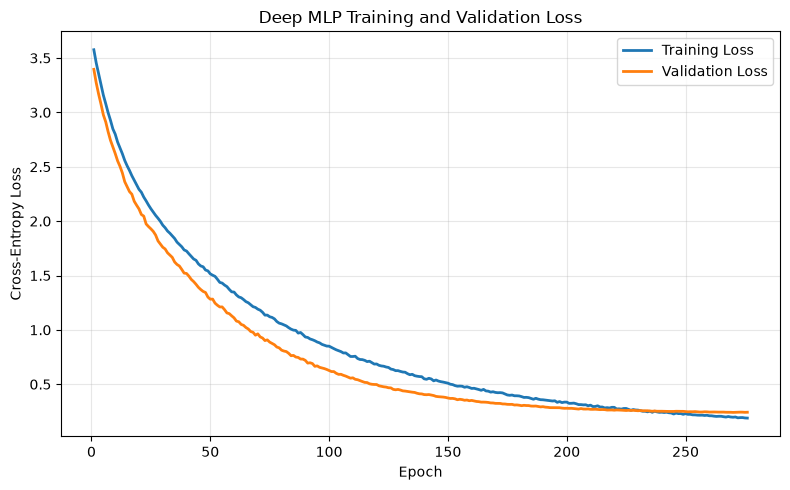


Saved:
F:\GeneformerProject\results\classifier_study\deep_mlp\deep_mlp_training_validation_loss.png


In [46]:
# ============================================================
# PLOT TRAINING AND VALIDATION LOSS
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
import os

# Convert training history to DataFrame
history_df = pd.DataFrame(training_history)

print("History columns:")
print(history_df.columns.tolist())

print("\nFirst rows:")
print(history_df.head())


# ============================================================
# PLOT LOSS
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history_df["Epoch"],
    history_df["Train_Loss"],
    label="Training Loss",
    linewidth=2
)

plt.plot(
    history_df["Epoch"],
    history_df["Val_Loss"],
    label="Validation Loss",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")

plt.title(
    "Deep MLP Training and Validation Loss"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()


# ============================================================
# SAVE FIGURE
# ============================================================

loss_plot_path = os.path.join(
    RESULTS_DIR,
    "deep_mlp",
    "deep_mlp_training_validation_loss.png"
)

plt.savefig(
    loss_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(loss_plot_path)

Test labels shape: (1659,)
Probability shape: (1659, 33)
Prediction shape: (1659,)
Probability range: 9.317717e-08 to 0.9990044
Probability sum for first sample: 1.0


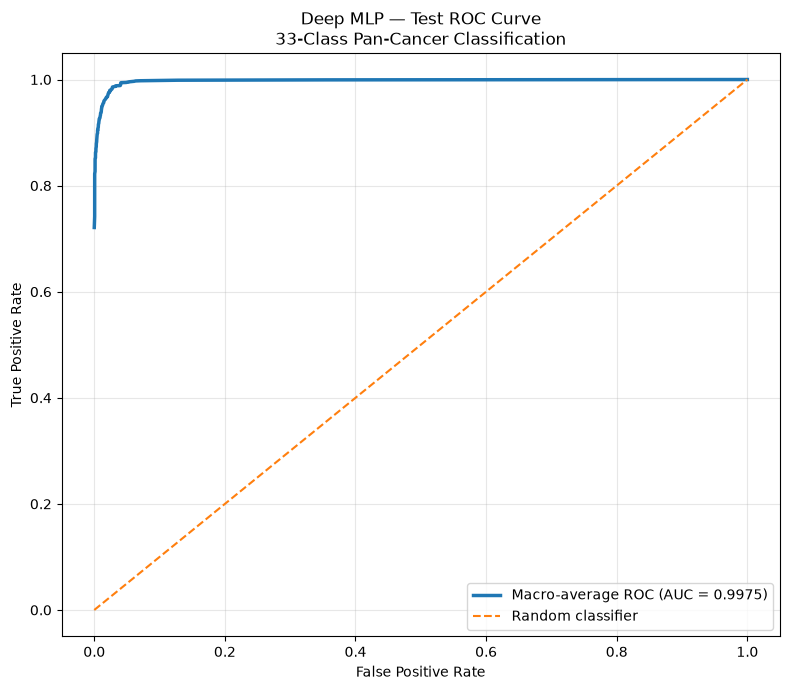

Macro ROC-AUC: 0.9975
Saved: F:\GeneformerProject\results\classifier_study\deep_mlp\deep_mlp_test_macro_roc.png
Deep MLP Macro AUC:    0.9972
Deep MLP Weighted AUC: 0.9975


In [47]:
# ============================================================
# DEEP MLP — TEST PREDICTIONS AND PROBABILITIES
# ============================================================

deep_mlp.eval()

with torch.no_grad():

    test_logits = deep_mlp(
        X_test_deep.to(device)
    )

    # Convert logits to probabilities
    deep_mlp_scores = torch.softmax(
        test_logits,
        dim=1
    ).cpu().numpy()

    # Predicted cancer class
    deep_mlp_test_pred = np.argmax(
        deep_mlp_scores,
        axis=1
    )


# ============================================================
# CHECK
# ============================================================

print("Test labels shape:",
      y_test.shape)

print("Probability shape:",
      deep_mlp_scores.shape)

print("Prediction shape:",
      deep_mlp_test_pred.shape)

print(
    "Probability range:",
    deep_mlp_scores.min(),
    "to",
    deep_mlp_scores.max()
)

print(
    "Probability sum for first sample:",
    deep_mlp_scores[0].sum()
)

# ============================================================
# DEEP MLP — TEST ROC
# ============================================================

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import numpy as np
import matplotlib.pyplot as plt

y_test_bin = label_binarize(
    y_test,
    classes=np.arange(len(cancer_names))
)

fpr = {}
tpr = {}
roc_auc = {}

for i in range(len(cancer_names)):

    fpr[i], tpr[i], _ = roc_curve(
        y_test_bin[:, i],
        deep_mlp_scores[:, i]
    )

    roc_auc[i] = auc(
        fpr[i],
        tpr[i]
    )


# ============================================================
# MACRO-AVERAGE ROC
# ============================================================

all_fpr = np.unique(
    np.concatenate([
        fpr[i]
        for i in range(len(cancer_names))
    ])
)

mean_tpr = np.zeros_like(all_fpr)

for i in range(len(cancer_names)):

    mean_tpr += np.interp(
        all_fpr,
        fpr[i],
        tpr[i]
    )

mean_tpr /= len(cancer_names)

macro_auc = auc(
    all_fpr,
    mean_tpr
)


# ============================================================
# PLOT
# ============================================================

plt.figure(figsize=(8, 7))

plt.plot(
    all_fpr,
    mean_tpr,
    linewidth=2.5,
    label=f"Macro-average ROC (AUC = {macro_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "Deep MLP — Test ROC Curve\n"
    "33-Class Pan-Cancer Classification"
)

plt.legend(
    loc="lower right"
)

plt.grid(alpha=0.3)

plt.tight_layout()

roc_plot_path = os.path.join(
    RESULTS_DIR,
    "deep_mlp",
    "deep_mlp_test_macro_roc.png"
)

plt.savefig(
    roc_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Macro ROC-AUC: {macro_auc:.4f}")
print("Saved:", roc_plot_path)

from sklearn.metrics import roc_auc_score

deep_mlp_macro_auc = roc_auc_score(
    y_test,
    deep_mlp_scores,
    multi_class="ovr",
    average="macro"
)

deep_mlp_weighted_auc = roc_auc_score(
    y_test,
    deep_mlp_scores,
    multi_class="ovr",
    average="weighted"
)

print("Deep MLP Macro AUC:   ", round(deep_mlp_macro_auc, 4))
print("Deep MLP Weighted AUC:", round(deep_mlp_weighted_auc, 4))